# AgentAccess

**Authors:** Alexander Michels

This notebook walks through the a generalized Agent-Based Model for spatial accessibility analysis.

In [1]:
import access
import geopandas as gpd
from IPython.display import Image
import math
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from tqdm import tqdm
import sys
sys.path.append("../")
from agentaccess.Model import AgentAccess
# pandas gives warnings too often
pd.options.mode.chained_assignment = None

In [2]:
figsize=(10,10)

## Data

The AgentAccess model has the exact same data requirements as traditional place-based spatial accessibility methods:

* demand: a population of people needing a good/service
* supply: a good/service distributed across space
* spatial impedance: the "cost" to overcome the distances between supply and demand

We will first load our population dataset, the general population within Cook County, IL.

In [3]:
pop = access.Datasets.load_data('chi_pop')
pop = access.Datasets.load_data("cook_county_tracts").merge(pop, on="geoid")
pop["geoid"] = pop["geoid"].astype(str)
pop.head()

,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,geoid,geometry,pop
0,1400000US17031440300,17,031,440300,4403,Tract,0.499,17031440300,"POLYGON ((359779.998 563694.9, 359785.854 5634...",4757
1,1400000US17031440600,17,031,440600,4406,Tract,0.259,17031440600,"POLYGON ((359797.31 563086.247, 359800.394 562...",2080
2,1400000US17031440700,17,031,440700,4407,Tract,0.126,17031440700,"POLYGON ((360201.128 563098.184, 360402.583 56...",1545
3,1400000US17031460200,17,031,460200,4602,Tract,0.232,17031460200,"POLYGON ((364927.536 564034.757, 365032.657 56...",2385
4,1400000US17031460600,17,031,460600,4606,Tract,0.101,17031460600,"POLYGON ((364641.501 563219.094, 364699.974 56...",1183


<Axes: >

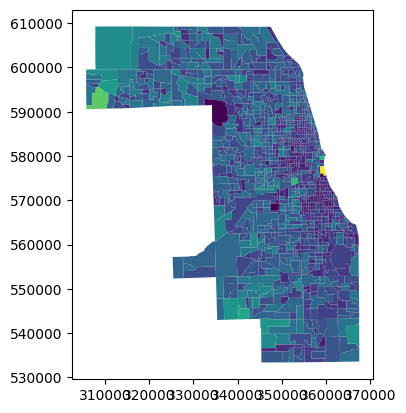

In [4]:
pop.plot(column="pop")

In [5]:
# load the dentists
dentist = access.Datasets.load_data("chi_doc")
dentist["geoid"] = dentist["geoid"].astype(str)
dentist = pop[["geoid", "geometry"]].merge(dentist, on="geoid")
dentist = dentist[dentist["dentist"] > 0]
dentist.head()

,geoid,geometry,doc,dentist
3,17031460200,"POLYGON ((364927.536 564034.757, 365032.657 56...",2,1
5,17031480100,"POLYGON ((362631.94 562768.039, 362344.056 562...",0,2
8,17031491200,"POLYGON ((358350.169 557376.361, 358249.857 55...",0,2
15,17031570400,"POLYGON ((351486.523 570724.319, 351295.619 57...",0,1
22,17031620100,"POLYGON ((350710.553 570130.081, 351295.619 57...",0,1


<Axes: >

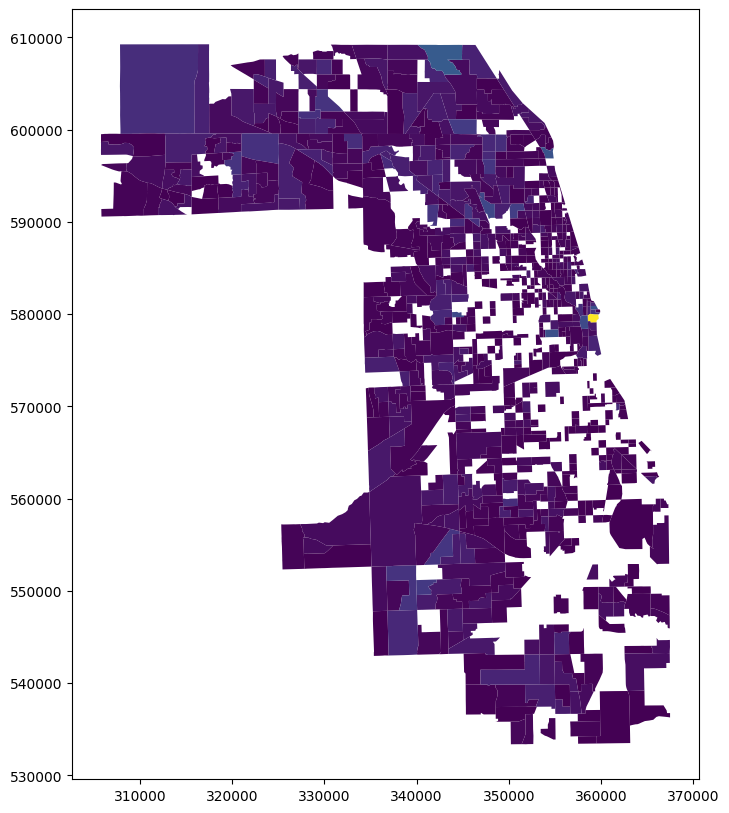

In [6]:
dentist.plot(column="dentist", figsize=figsize)

In [7]:
# get car travel times
chi_travel_costs = access.Datasets.load_data('chi_times')
chi_travel_costs["origin"] = chi_travel_costs["origin"].astype(str)
chi_travel_costs["dest"] = chi_travel_costs["dest"].astype(str)
chi_travel_costs.head()

,origin,dest,cost
0,17093890101,17031010100,91.20
1,17093890101,17031010201,92.82
2,17093890101,17031010202,92.95
3,17093890101,17031010300,89.40
4,17093890101,17031010400,84.97


## Model

The model executes across a number of time steps set by the user.

In [8]:
time_steps = 10

In [9]:
# intialize our model
model = AgentAccess(
    pop,
    "geoid",
    "pop",
    dentist,
    "geoid",
    "dentist",
    chi_travel_costs,
    "origin",
    "dest",
    "cost",
    time_steps,
    pop_per_agent=1000,
    output_path="../outputs/",
    processes=16,
)

In [10]:
model.run_model()

Running Model: 100%|██████████████████████████████████████| 10/10 [6:05:25<00:00, 2192.51s/it]


In [11]:
model.save_gif()

Let's view the gif from the model!

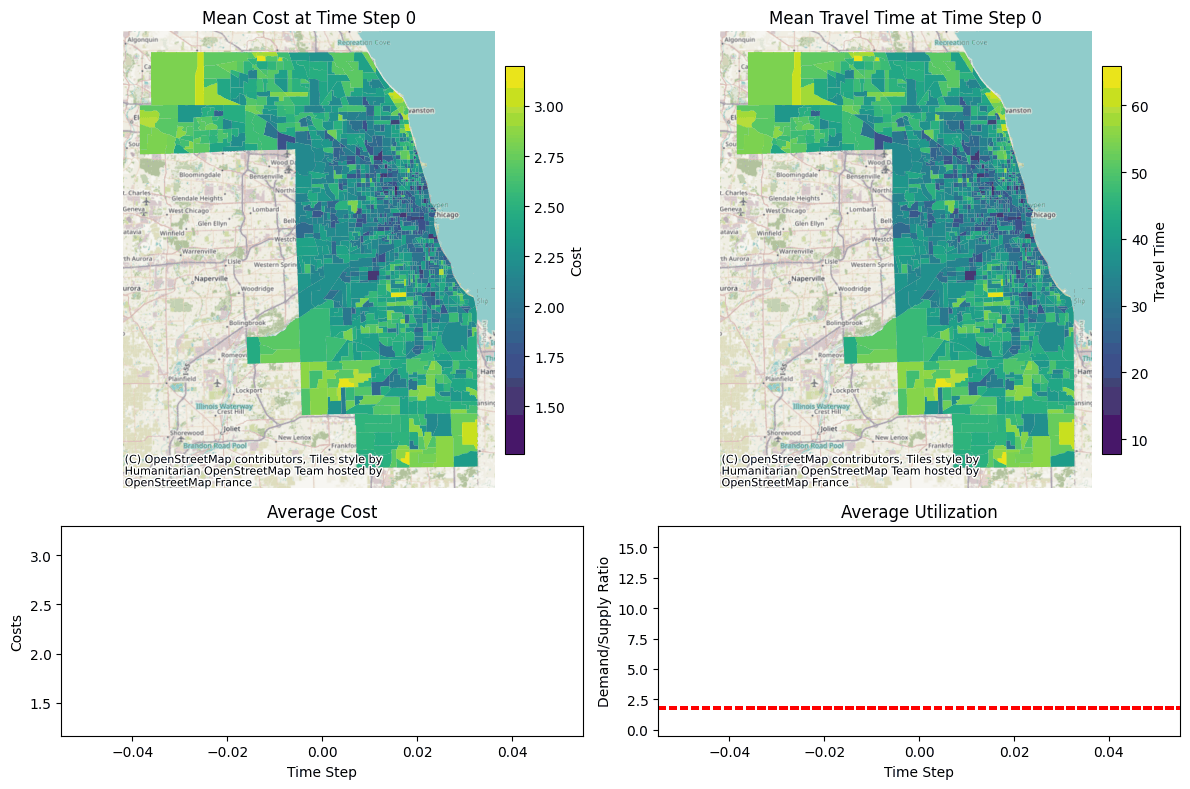

In [12]:
Image(filename=os.path.join(model.output_dir, "movie.gif"))

We can also inspect all of the internal data that our model generated:

In [13]:
model.cost_df.head()

cost
origin      dest             
17031010100 17031010100  0.17
            17031010201  5.70
            17031010202  2.63
            17031010300  3.58
            17031010400  8.53

In [14]:
model.demand_df.head()

,ID,GEOID,Cost Field,tau,Choice 0,Cost 0,Choice 1,Cost 1,Choice 2,Cost 2,...,Choice 5,Cost 5,Choice 6,Cost 6,Choice 7,Cost 7,Choice 8,Cost 8,Choice 9,Cost 9
0,0,17031440300,cost,30,17031823604,2.261667,17031650500,2.410491,17031822400,1.781749,...,17031040900,2.812753,17031081600,2.768733,17031824115,1.826592,17031060900,2.910374,17031803800,2.474911
1,1,17031440300,cost,30,17031827802,1.644000,17031804102,2.386880,17031840400,2.587442,...,17031031300,2.603753,17031060900,2.852484,17031240300,2.854501,17031020801,2.558625,17031838200,0.972378
2,2,17031440300,cost,30,17031480100,1.569333,17031839100,0.750563,17031828801,2.128834,...,17031819600,3.650946,17031020801,2.544732,17031808500,3.169138,17031261000,2.759374,17031823002,4.249726
3,3,17031440300,cost,30,17031580501,1.751667,17031823604,1.706263,17031380500,4.292884,...,17031030604,2.974633,17031261000,2.840421,17031040900,3.241471,17031251100,3.558985,17031824114,3.255321
4,4,17031440300,cost,30,17031071200,1.986667,17031824122,3.993726,17031110400,2.866484,...,17031818000,2.932810,17031251100,3.524251,17031031300,2.794295,17031100200,2.030571,17031806802,3.881811


In [15]:
model.supply_df.head()

,geometry,Supply,Demand 0,D/S Ratio 0,Demand 1,D/S Ratio 1,Demand 2,D/S Ratio 2,Demand 3,D/S Ratio 3,...,Demand 5,D/S Ratio 5,Demand 6,D/S Ratio 6,Demand 7,D/S Ratio 7,Demand 8,D/S Ratio 8,Demand 9,D/S Ratio 9
GEOID,,,,,,,,,,,,,,,,,,,,,
17031010100,"POLYGON ((355348.227 594458.329, 355268.012 59...",1,4.0,4.0,3.0,3.0,3.0,3.0,4.0,4.0,...,3.0,3.0,4.0,4.0,4.0,4.0,4.0,4.0,2.0,2.0
17031010201,"POLYGON ((353878.616 594469.566, 353976.44 594...",1,0.0,0.0,1.0,1.0,1.0,1.0,2.0,2.0,...,2.0,2.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0
17031010202,"POLYGON ((354561.376 593715.902, 354492.559 59...",1,4.0,4.0,3.0,3.0,2.0,2.0,3.0,3.0,...,1.0,1.0,3.0,3.0,3.0,3.0,4.0,4.0,2.0,2.0
17031010300,"POLYGON ((355453.969 594110.361, 355490.4 5939...",1,0.0,0.0,4.0,4.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
17031010400,"POLYGON ((355646.47 593476.983, 355687.191 593...",2,0.0,0.0,3.0,1.5,0.0,0.0,1.0,0.5,...,0.0,0.0,1.0,0.5,0.0,0.0,2.0,1.0,0.0,0.0


In [16]:
model.spatial_units_df.head()

,Demand,geometry,Cost 0,D/S Ratio 0,Time 0,Cost 1,D/S Ratio 1,Time 1,Cost 2,D/S Ratio 2,...,Time 6,Cost 7,D/S Ratio 7,Time 7,Cost 8,D/S Ratio 8,Time 8,Cost 9,D/S Ratio 9,Time 9
GEOID,,,,,,,,,,,,,,,,,,,,,
17031440300,4757,"POLYGON ((359779.998 563694.9, 359785.854 5634...",1.842667,2.851429,25.18,2.249585,1.971000,37.494,2.731478,2.973810,...,30.620000,2.777199,4.115789,34.816000,2.763586,3.331429,33.118000,2.966829,2.770370,42.236000
17031440600,2080,"POLYGON ((359797.31 563086.247, 359800.394 562...",2.497333,3.611111,44.82,2.397202,2.555556,48.660,2.725862,3.777778,...,21.073333,2.631406,2.724359,38.703333,2.673660,2.141026,38.990000,2.653572,2.551282,38.990000
17031440700,1545,"POLYGON ((360201.128 563098.184, 360402.583 56...",2.593000,1.472222,47.69,2.643636,2.333333,44.475,2.482239,2.666667,...,61.065000,2.926324,1.517857,61.065000,3.136151,3.363636,48.325000,2.402816,3.812500,29.030000
17031460200,2385,"POLYGON ((364927.536 564034.757, 365032.657 56...",2.383000,1.150000,41.39,3.014271,2.308333,40.450,3.835303,4.928571,...,47.543333,4.274213,4.666667,47.543333,4.262635,5.333333,47.543333,4.294796,5.333333,47.543333
17031460600,1183,"POLYGON ((364641.501 563219.094, 364699.974 56...",2.550333,1.916667,46.41,2.044883,0.978365,52.750,2.133551,5.333333,...,49.260000,2.946951,3.178571,36.335000,3.326277,2.750000,38.730000,4.126268,5.000000,39.400000


In [17]:
def normalize_columns(df, columns, to_flip=[]):
    for column in columns:
        df[column] = (df[column] - df[column].min()) / (df[column].max() - df[column].min())
        if column in to_flip:
            df[column] = 1 - df[column]
    return df

def average_columns(df, new_column, columns_to_average):
    df[new_column] = df[columns_to_average].mean(axis=1)
    return df

ABMs have some randomness, so to account for this, we will take averages over the last half of the time steps:

In [18]:
last_portion = 2
df = average_columns(model.spatial_units_df, "D/S Ratio", [f"D/S Ratio {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = average_columns(df, "Time", [f"Time {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = average_columns(df, "Cost", [f"Cost {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = df[["D/S Ratio", "Time", "Cost", "geometry"]]
df.head()

,D/S Ratio,Time,Cost,geometry
GEOID,,,,
17031440300,3.752851,35.015200,2.881744,"POLYGON ((359779.998 563694.9, 359785.854 5634..."
17031440600,2.719841,31.993333,2.618846,"POLYGON ((359797.31 563086.247, 359800.394 562..."
17031440700,2.328084,52.110000,2.864599,"POLYGON ((360201.128 563098.184, 360402.583 56..."
17031460200,4.854762,47.157333,3.991803,"POLYGON ((364927.536 564034.757, 365032.657 56..."
17031460600,3.285714,42.068000,3.097441,"POLYGON ((364641.501 563219.094, 364699.974 56..."


In [19]:
cols = ["D/S Ratio", "Time", "Cost"]
model_result = df
# model_result = normalize_columns(df, columns=cols)
model_result.head()

,D/S Ratio,Time,Cost,geometry
GEOID,,,,
17031440300,3.752851,35.015200,2.881744,"POLYGON ((359779.998 563694.9, 359785.854 5634..."
17031440600,2.719841,31.993333,2.618846,"POLYGON ((359797.31 563086.247, 359800.394 562..."
17031440700,2.328084,52.110000,2.864599,"POLYGON ((360201.128 563098.184, 360402.583 56..."
17031460200,4.854762,47.157333,3.991803,"POLYGON ((364927.536 564034.757, 365032.657 56..."
17031460600,3.285714,42.068000,3.097441,"POLYGON ((364641.501 563219.094, 364699.974 56..."


<Axes: >

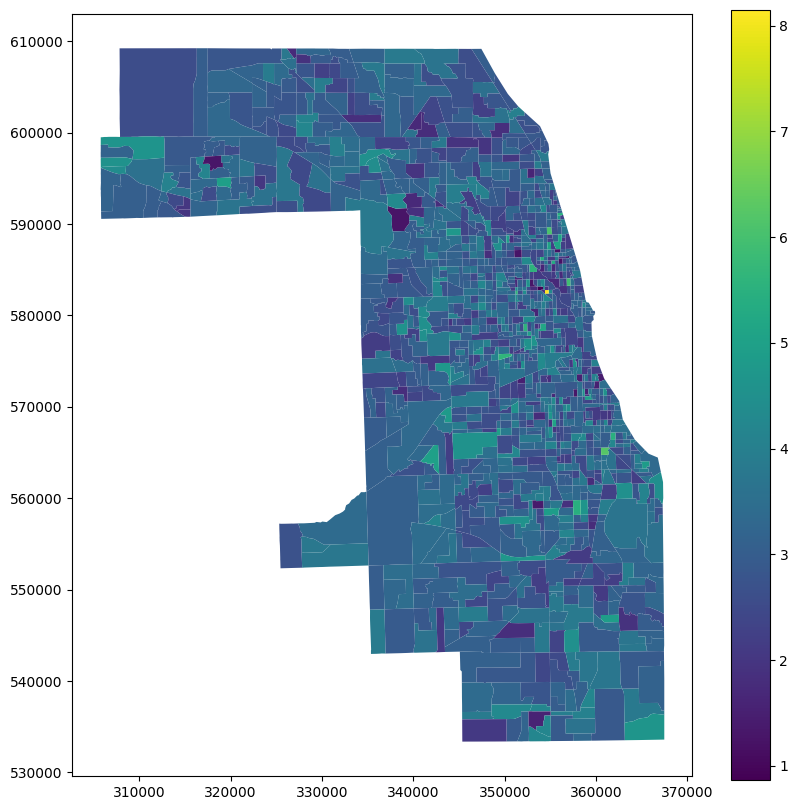

In [20]:
model_result.plot(column="D/S Ratio", figsize=figsize, legend=True)

<Axes: >

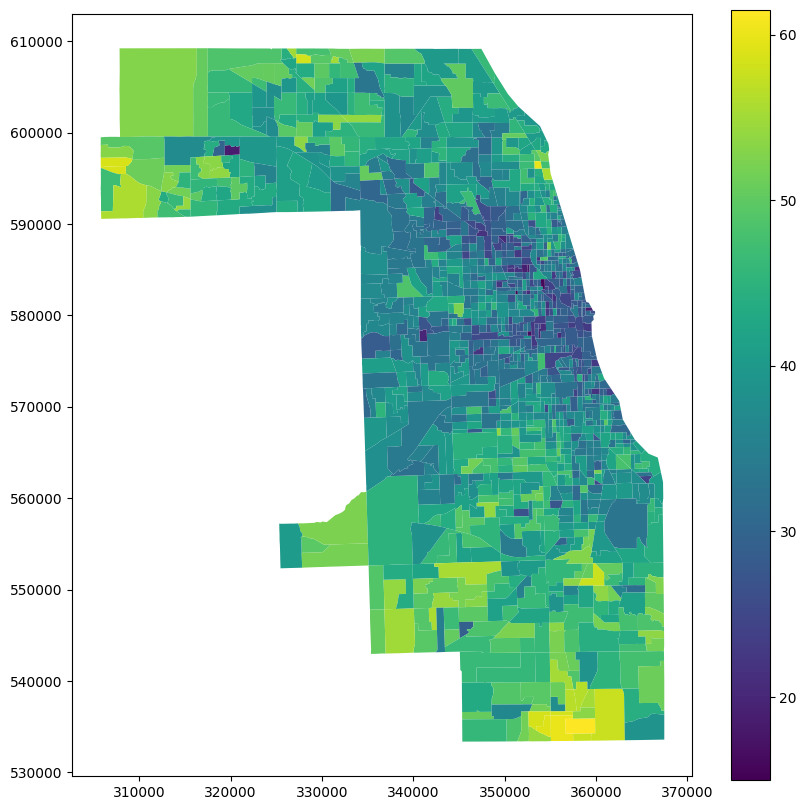

In [21]:
model_result.plot(column="Time", figsize=figsize, legend=True)

<Axes: >

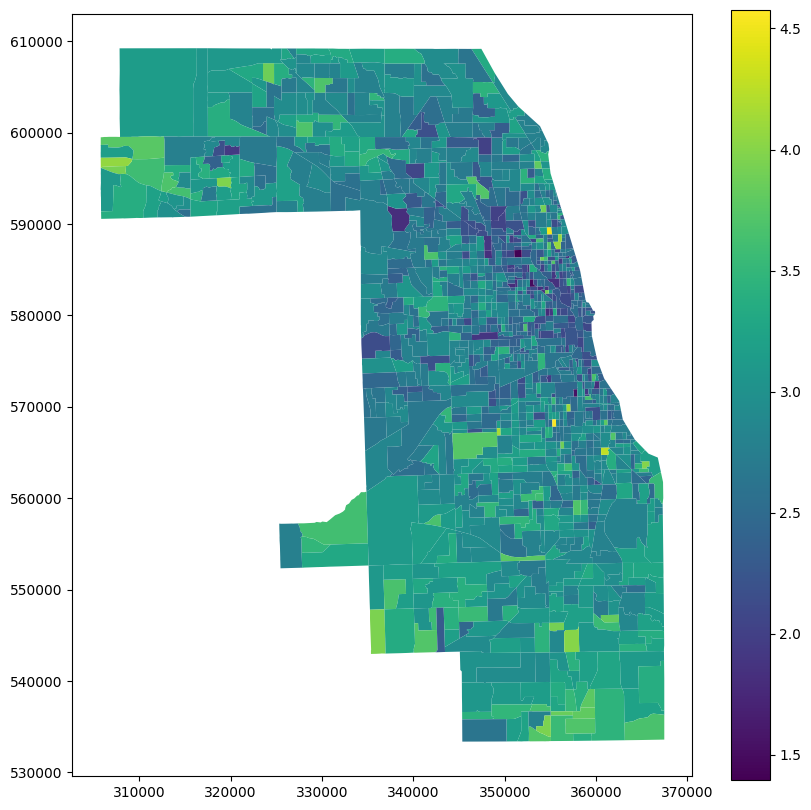

In [22]:
model_result.plot(column="Cost", figsize=figsize, legend=True)

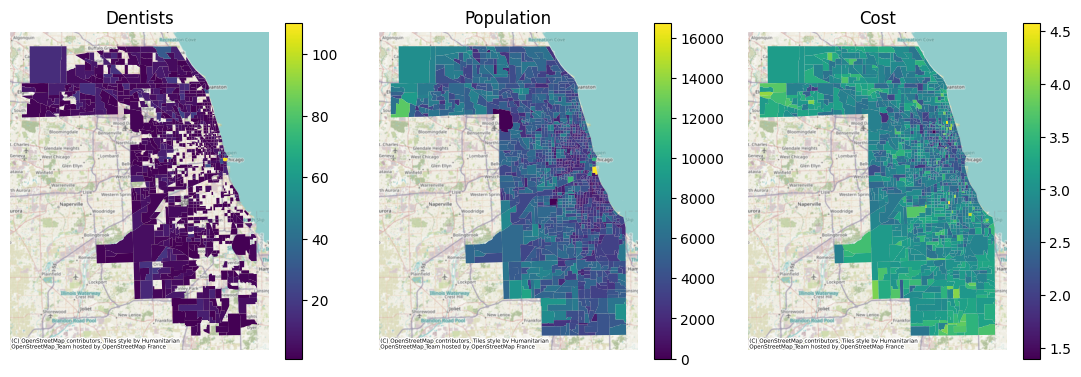

In [37]:
import contextily as cx
fig, axes = plt.subplots(nrows=1, ncols=3,figsize=(11,3.75))
dentist.plot(column='dentist', legend=True, ax=axes[0])
pop.plot(column="pop", legend=True, ax=axes[1])
model_result.plot(column="Cost", ax=axes[2], legend=True)
for ax, gdf, title in zip(axes, [dentist, pop, model_result], ["Dentists", "Population", "Cost"]):
    cx.add_basemap(ax=ax, crs=gdf.crs.to_string(), attribution_size=4)
    ax.axis('off')
    ax.set_title(title)
fig.tight_layout()
plt.savefig("../examples/DentistOverview.png")